# knob-senses — servidor TCP de dados

In [1]:
import sys
from pathlib import Path

sys.path.insert(0, Path.cwd().parent / 'models' / 'src')
from common import contract, data, paths, server

AXES = server.AXES

HOST = server.HOST
PORTA = server.PORT
HZ = 1.0

# Um stdout REDIRECIONADO (pipe, arquivo, `jupyter nbconvert --execute`) no
# Windows cai no codepage da locale (cp1252), e ai o travessao do log vira o
# byte 0x97 — que nao e UTF-8 valido. Quem le o pipe com utf-8 quebra no meio.
# Num console interativo ou no Jupyter o Python ja acerta; isto e para o resto.
# O OutStream do Jupyter nao tem reconfigure(), dai o AttributeError no guard.
for _s in (sys.stdout, sys.stderr):
    try:
        _s.reconfigure(encoding="utf-8", errors="replace")
    except (AttributeError, ValueError):
        pass


DATA_SOURCE = paths.PROCESSED
print(f"dados em {DATA_SOURCE}", flush=True)

dados em C:\Users\gusta\Documents\PlatformIO\Projects\knob-senses\data\processed


In [18]:
df = data.load_split('test').reset_index()

for f, df in df.groupby('inversor'):
  print(f"  {DATA_SOURCE.name:10} {f:16} {len(df):7} amostras")


  processed  ifpee1               354 amostras


In [20]:
for sample in df[df.index < 5].iloc:
    print(server.sample_bytes(sample))


b'C\x8a\xf7AS\xb5-D\x89,FB'
b'(\x00\xf5A\x9a\xb7\x1cDa\xa0=B'
b'q\xb4\xf6AV\xc6,DC[EB'
b'A\x08\xfaA\xc9L"D\x96\x88BB'
b")\xb4\xfeA\x88\x10'D\xfe\xe8FB"


In [21]:
reply = dict()
for f, df in df.groupby("inversor"): 
  reply[f] = (server.serve(df, paths.EVAL_LOG.parent / f"{f}_val.csv"))


Server started at 0.0.0.0:3333
sample 2025-01-01 00:00:00: real=140.1100, pred=147.6193, err=7.5093
sample 2025-01-02 00:00:00: real=124.2500, pred=128.1863, err=3.9363
sample 2025-01-03 00:00:00: real=134.1400, pred=148.1111, err=13.9711
sample 2025-01-04 00:00:00: real=129.6900, pred=124.7333, err=4.9567
sample 2025-01-05 00:00:00: real=132.1000, pred=128.9820, err=3.1180
sample 2025-01-06 00:00:00: real=123.1500, pred=122.8640, err=0.2860
sample 2025-01-07 00:00:00: real=144.6300, pred=140.3229, err=4.3071
sample 2025-01-08 00:00:00: real=123.9500, pred=132.5803, err=8.6303
sample 2025-01-09 00:00:00: real=118.9600, pred=124.5064, err=5.5464
sample 2025-01-10 00:00:00: real=102.6300, pred=102.8064, err=0.1764
sample 2025-01-11 00:00:00: real=101.3400, pred=111.3590, err=10.0190
sample 2025-01-12 00:00:00: real=96.9700, pred=97.4861, err=0.5161
sample 2025-01-13 00:00:00: real=93.4100, pred=96.7421, err=3.3321
sample 2025-01-14 00:00:00: real=84.0000, pred=85.4229, err=1.4229
sample 

In [4]:
import pandas as pd

from common import paths


def carrega_avaliacoes():
    """reply da sessao (se existir) ou os logs ifpe*_val.csv; ignora vazios."""
    if "reply" in globals() and reply:
        return {f: df.copy() for f, df in reply.items() if len(df)}
    avaliacoes = {}
    for log in sorted(paths.EVAL_LOG.parent.rglob("ifpe*.csv")):
        d = pd.read_csv(log, parse_dates=["sample"])
        if not d.empty:
            avaliacoes[log.stem.replace("_val", "")] = d
    return avaliacoes


AVALIACOES = carrega_avaliacoes()
print("avaliações:", {k: len(v) for k, v in AVALIACOES.items()})


avaliações: {'ifpee1': 354}


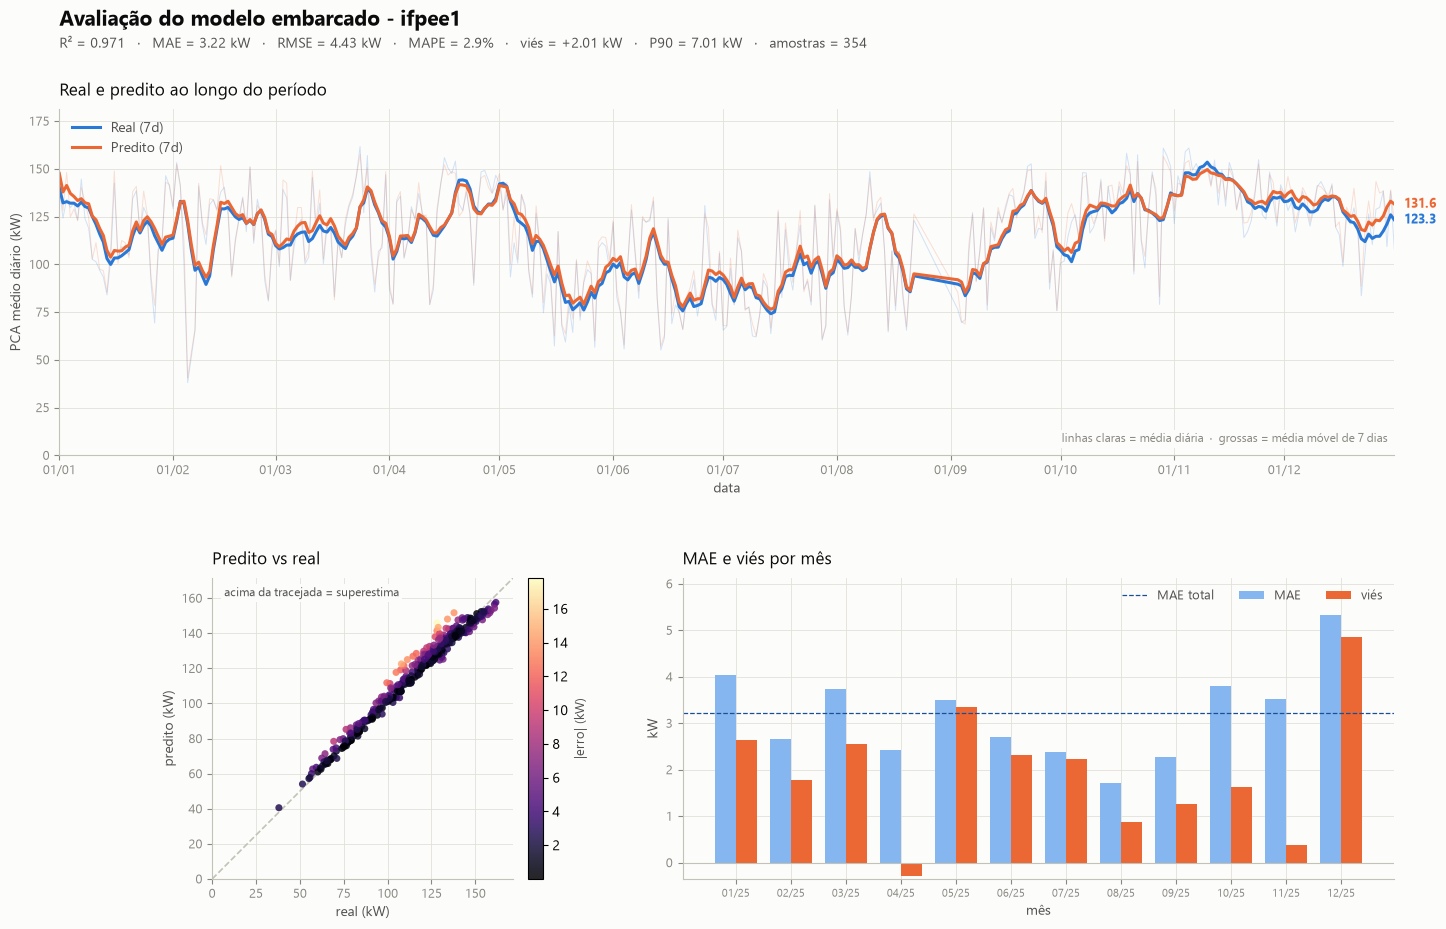

In [7]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.gridspec import GridSpec

from common import plots, server
from common.plots import (SUPERFICIE, TINTA, TINTA_2, MUDO, GRADE, EIXO,
                          REAL, PREDITO, ERRO_CLARO, MAE_ESC, HALO, enfeitar)

plots.aplicar_estilo()


def plot(df_eval: pd.DataFrame, id):
    """Painel diario de real x predito e erro absoluto.

    `df_eval` vem do log do servidor (sample, real, pred, err) ou do `reply`.
    """
    d = df_eval.copy()
    d["sample"] = pd.to_datetime(d["sample"])
    d = d.sort_values("sample").reset_index(drop=True)
    m = server.eval_metrics(d)
    r2, mae, rmse = m["r2"], m["mae"], m["rmse"]
    mape, p90, vies = m["mape"], m["p90"], m["vies"]

    # Agrega por dia: medias (funciona para log diario ou horario).
    df_dia = (d.assign(dia=d["sample"].dt.floor("D"))
               .groupby("dia", as_index=False)
               .agg(real=("real", "mean"), pred=("pred", "mean"),
                    err_abs=("err", lambda s: float(np.abs(s).mean()))))
    x1 = df_dia["dia"]
    janela = min(7, len(df_dia))
    real_l = df_dia["real"].rolling(janela, min_periods=1).mean()
    pred_l = df_dia["pred"].rolling(janela, min_periods=1).mean()
    ymax = float(np.nanmax([df_dia["real"].max(), df_dia["pred"].max()])) * 1.12

    fig = plt.figure(figsize=(15, 9.5))
    gs = GridSpec(2, 2, figure=fig, height_ratios=[1.15, 1.0],
                  width_ratios=[1.0, 1.45], hspace=0.38, wspace=0.22)

    # 1. real vs predito ao longo do periodo
    ax = fig.add_subplot(gs[0, :])
    ax.plot(x1, df_dia["real"], color=REAL, lw=0.7, alpha=0.20)
    ax.plot(x1, df_dia["pred"], color=PREDITO, lw=0.7, alpha=0.20)
    ax.plot(x1, real_l, color=REAL, lw=2.2, label=f"Real ({janela}d)")
    ax.plot(x1, pred_l, color=PREDITO, lw=2.2, label=f"Predito ({janela}d)")
    enfeitar(ax, "Real e predito ao longo do período", "data",
             "PCA médio diário (kW)")
    ax.set_xlim(x1.iloc[0], x1.iloc[-1])
    ax.set_ylim(0.0, ymax)
    ticks = pd.date_range(x1.iloc[0], x1.iloc[-1], freq="MS")
    ax.set_xticks(ticks)
    ax.set_xticklabels([t.strftime("%d/%m") for t in ticks])
    for serie, cor in ((real_l, REAL), (pred_l, PREDITO)):
        ax.annotate(f"{serie.iloc[-1]:.1f}", (x1.iloc[-1], serie.iloc[-1]),
                    xytext=(7, 0), textcoords="offset points", color=cor,
                    fontsize=9, va="center", fontweight="bold")
    ax.legend(frameon=False, loc="upper left", fontsize=10, labelcolor=TINTA_2)
    ax.text(0.995, 0.03,
            f"linhas claras = média diária  ·  grossas = média móvel de {janela} dias",
            transform=ax.transAxes, ha="right", va="bottom", color=MUDO,
            fontsize=8.5, bbox=HALO)

    # 2. predito vs real, colorido pelo erro absoluto
    ax = fig.add_subplot(gs[1, 0])
    lim = (0.0, float(max(df_dia["real"].max(), df_dia["pred"].max())) * 1.06)
    ax.plot(lim, lim, color=EIXO, lw=1.2, linestyle="--", zorder=1)
    sc = ax.scatter(df_dia["real"], df_dia["pred"],
                    c=df_dia["err_abs"], cmap="magma", s=26, alpha=0.85,
                    linewidths=0, zorder=2)
    cb = fig.colorbar(sc, ax=ax, fraction=0.046, pad=0.03)
    cb.set_label("|erro| (kW)", color=TINTA_2, fontsize=9)
    ax.text(lim[1] * 0.04, lim[1] * 0.97, "acima da tracejada = superestima",
            color=TINTA_2, fontsize=8.5, va="top", bbox=HALO)
    ax.set_aspect("equal")
    ax.set_xlim(lim)
    ax.set_ylim(lim)
    enfeitar(ax, "Predito vs real", "real (kW)", "predito (kW)")

        # 3. MAE e viés por mês -- o resumo que interessa para diagnóstico
    d["abs_err"] = np.abs(d["pred"] - d["real"])
    d["signed_err"] = d["pred"] - d["real"]
    df_mes = (d.assign(mes=d["sample"].dt.to_period("M"))
               .groupby("mes", as_index=False)
               .agg(mae=("abs_err", "mean"), vies=("signed_err", "mean"),
                    n=("real", "size")))
    ax = fig.add_subplot(gs[1, 1])
    xm = np.arange(len(df_mes))
    w = 0.38
    ax.bar(xm - w / 2, df_mes["mae"], w, color=ERRO_CLARO, label="MAE")
    ax.bar(xm + w / 2, df_mes["vies"], w, color=PREDITO, label="viés")
    ax.axhline(0, color=EIXO, lw=0.8)
    ax.axhline(mae, color=MAE_ESC, lw=0.9, ls="--", label="MAE total")
    enfeitar(ax, "MAE e viés por mês", "mês", "kW")
    ax.set_xticks(xm)
    ax.set_xticklabels([m.strftime("%m/%y")
                        for m in df_mes["mes"].dt.to_timestamp()], fontsize=8)
    ymin = min(0.0, float(df_mes["vies"].min())) * 1.20
    ymax = max(mae, float(df_mes["mae"].max()), float(df_mes["vies"].max())) * 1.15
    ax.set_ylim(ymin, ymax)
    ax.legend(frameon=False, loc="upper right", fontsize=9,
              labelcolor=TINTA_2, ncol=3)

    fig.suptitle(f"Avaliação do modelo embarcado - {id}", color=TINTA,
                 fontsize=15, x=0.07, ha="left", y=0.985, fontweight="bold")
    fig.text(0.07, 0.945,
             f"R² = {r2:.3f}   ·   MAE = {mae:.2f} kW   ·   RMSE = {rmse:.2f} kW"
             f"   ·   MAPE = {mape:.1f}%   ·   viés = {vies:+.2f} kW"
             f"   ·   P90 = {p90:.2f} kW   ·   amostras = {len(d)}",
             color=TINTA_2, fontsize=10, ha="left")
    fig.subplots_adjust(top=0.88, bottom=0.07, left=0.07, right=0.96)
    plt.show()
    return fig


for inversor, df_eval in AVALIACOES.items():
    plot(df_eval.copy(), inversor)


In [8]:
import pandas as pd
from IPython.display import display

from common import server


def linha(inversor, periodo, df):
    m = server.eval_metrics(df)
    return {
        "inversor": inversor, "período": periodo, "n": m["amostras"],
        "MAE": m["mae"], "RMSE": m["rmse"], "R²": m["r2"],
        "viés": m["vies"], "MAPE (%)": m["mape"], "P90": m["p90"],
    }


linhas = []
for inversor, df in AVALIACOES.items():
    d = df.copy()
    d["sample"] = pd.to_datetime(d["sample"])
    d = d.sort_values("sample")
    linhas.append(linha(inversor, "total", d))
    for periodo, g in d.groupby(d["sample"].dt.to_period("M")):
        linhas.append(linha(inversor, str(periodo), g))

if linhas:
    tabela = pd.DataFrame(linhas).set_index(["inversor", "período"])
    display(
        tabela.style.format({
            "n": "{:d}",
            "MAE": "{:.2f}", "RMSE": "{:.2f}", "R²": "{:.3f}",
            "viés": "{:+.2f}", "MAPE (%)": "{:.1f}%", "P90": "{:.2f}",
        }).set_caption("Métricas de avaliação — log atual")
    )
else:
    print("sem avaliações para tabular")
